## Setup

In [15]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import statsmodels.formula.api as smf
import statsmodels.api as sm

from scipy.stats import linregress

import warnings
import sys
import os

import testis_model as tm

In [2]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,              # base font size
    'xtick.labelsize': 12,        # x-axis tick label size
    'ytick.labelsize': 12,        # y-axis tick label size
    'axes.labelsize': 12,         # axis label size
    'axes.titlesize': 12,         # title size
    'legend.fontsize': 12,        # legend font size
    'figure.titlesize': 12        # figure title size
})

In [3]:
df = pd.read_csv('../model_simulations/all_clone_results.csv')

# Only include data that has at least 2 observations
df = df.query('last_time > 5').copy()

print(f'The loaded clone data has {len(df)} rows.')

The loaded clone data has 34117 rows.


In [4]:
df['r_median'] = np.sqrt(df['lower'] * df['upper'])

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    df['log_r_median'] = np.where(
        df['r_median'] > 0,
        np.log10(df['r_median']),
        -np.inf
    )

df['l_gap'] = df['l_max'] - df['l_null']
df['pass_null'] = df['l_gap'] > 2

df.head()

,scenario,fish,clone,init_time,init_freq,last_time,max_time,max_freq,size,avg_freq_change,...,if_opt,l_max,lower,upper,if_null,l_null,r_median,log_r_median,l_gap,pass_null
0,n500_r15_y6,0,0,5.0,0.555256,25.0,26.0,0.0,0.285664,0.025606,...,0.551790,-212.780255,11.670349,70.666996,0.288180,-2317.466955,28.717739,1.458150,2104.686700,True
1,n500_r15_y6,0,1,5.0,0.311770,18.0,26.0,0.0,0.144305,0.023913,...,0.316866,-157.553822,10.354475,67.457306,0.144305,-3094.812299,26.428866,1.422079,2937.258477,True
2,n500_r15_y6,0,2,5.0,0.132974,26.0,26.0,1.0,0.570031,-0.041287,...,0.144224,-211.285386,10.235373,63.934861,0.569150,-5935.367621,25.581188,1.407921,5724.082235,True
3,n500_r15_y6,1,0,5.0,0.365678,14.0,26.0,0.0,0.122192,0.031347,...,0.369282,-120.251278,8.721297,104.718456,0.122192,-2597.410266,30.220535,1.480302,2477.158989,True
4,n500_r15_y6,1,1,5.0,0.331536,24.0,26.0,0.0,0.182390,0.014896,...,0.336038,-192.071656,9.610288,63.928778,0.183544,-1403.052886,24.786568,1.394216,1210.981230,True


## Bias

In [168]:
r_values = [0, 1, 4, 15, 36]
for r in r_values:
    scenario = f'n1000_r{r}_y6'
    r_opts = df.query(f'scenario == @scenario and pass_null')['r_opt']
    print(f'r = {r}:\t{np.mean(r_opts):.2f}\t+/- {np.std(r_opts)/np.sqrt(len(r_opts)):.2f}')

r = 0:	0.10	+/- 0.01
r = 1:	0.97	+/- 0.02
r = 4:	3.47	+/- 0.06
r = 15:	12.22	+/- 0.24
r = 36:	28.17	+/- 0.72


In [170]:
r_values = [0, 1, 4, 15, 36]
for r in r_values:
    scenario = f'n1000_r{r}_y6'
    r_opts = df.query(f'scenario == @scenario and pass_null')['r_median']
    print(f'r = {r}:\t{np.mean(r_opts):.2f}\t+/- {np.std(r_opts)/np.sqrt(len(r_opts)):.2f}')

r = 0:	0.01	+/- 0.01
r = 1:	0.95	+/- 0.02
r = 4:	3.76	+/- 0.07
r = 15:	13.91	+/- 0.29
r = 36:	32.75	+/- 0.86


## Compare drift distributions

In [159]:
# Define mapping from scenario string to numeric r
scenario_map = {
    'n1000_r1_y6': 1,
    'n1000_r4_y6': 4,
    'n1000_r15_y6': 15,
    'n1000_r36_y6': 36,
    'real': 'Exp. data'
}

df_plot = df[df['scenario'].isin(scenario_map.keys())].copy()
df_plot['scenario'] = df_plot['scenario'].map(scenario_map)

df_zero = df_plot.query('r_median == 0').copy()
df_nonzero = df_plot.query('r_median != 0').copy()

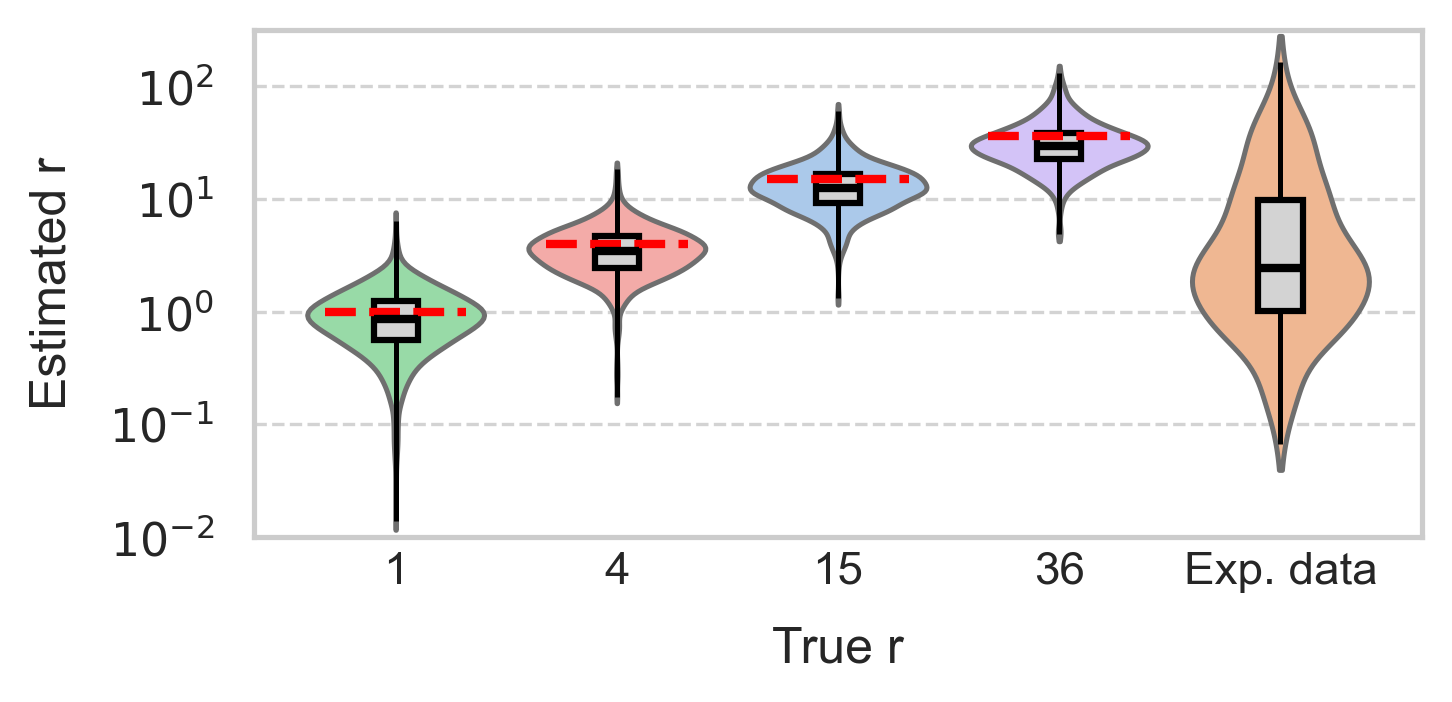

In [166]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(5,2.5), dpi=300)

# Violin plot
sns.violinplot(
    data=df_nonzero, x='scenario', y='log_r_median',
    order=[1, 4, 15, 36, 'Exp. data'],
    inner=None, cut=1, hue='scenario', density_norm='area',
    linewidth=1.2, palette="pastel", ax=ax, legend=False
)

# Overlay boxplot
sns.boxplot(
    data=df_nonzero, x='scenario', y='log_r_median',
    order=[1, 4, 15, 36, 'Exp. data'],
    whis=np.inf, width=0.2, showcaps=False,
    boxprops={'facecolor':'lightgray', 'edgecolor':'black', 'linewidth':1.5},
    whiskerprops={'color':'black', 'linewidth':1.2},
    capprops={'color':'black', 'linewidth':1.2},
    medianprops={'color':'black', 'linewidth':2},
    ax=ax
)

# Reference lines at log10(r)
for i, r in enumerate([1, 4, 15, 36]):
    ax.hlines(
        y=np.log10(r), xmin=i-0.32, xmax=i+0.32,
        colors='red', linestyles='dashed', linewidth=2
    )

# Axis labels
ax.set_xlabel("True r", fontsize=12, labelpad=8)
ax.set_ylabel("Estimated r", fontsize=12, labelpad=8)

# Set y‑ticks to powers of 10
# Choose the range based on your data
yticks = np.arange(-2, 3)   # gives 10^-2 through 10^2
ax.set_yticks(yticks)
ax.set_yticklabels([f"$10^{{{int(y)}}}$" for y in yticks])

ax.tick_params(axis='x', which='major', length=0, labelsize=11)
ax.tick_params(axis='y', labelsize=11)

ax.set_ylim([-2, 2.5])

ax.grid(True, axis='y', linestyle='--', linewidth=0.8, color='lightgray')

plt.tight_layout()
plt.show()

## Null hypothesis

In [13]:
model_simulations_path = os.path.abspath("../model_simulations")

# Add to sys.path if not already present
if model_simulations_path not in sys.path:
    sys.path.append(model_simulations_path)

print("Added to path:", model_simulations_path)
from saving_loading import find_scenarios, load_all_scenarios

scenarios_directory = os.path.join('..', 'model_simulations', 'scenarios')
fish_data, clone_data = load_all_scenarios('real', directory = scenarios_directory)

Added to path: /Users/connor/Documents/github/sperm-data-analysis/model_simulations


In [22]:
df.query('scenario == "real" and ~pass_null').sort_values('init_freq', ascending = False).head(3)

,scenario,fish,clone,init_time,init_freq,last_time,max_time,max_freq,size,avg_freq_change,...,if_opt,l_max,lower,upper,if_null,l_null,r_median,log_r_median,l_gap,pass_null
13805,real,23,0,4.86,0.986885,5.76,5.76,0.972509,0.978422,0.015974,...,0.800799,-28.122955,0.0,284.693553,0.782111,-28.904153,0.0,-inf,0.781199,False
13911,real,43,0,4.86,0.296460,5.76,5.76,0.119141,0.173442,0.197022,...,0.086886,-15.649594,0.0,193.529911,0.069154,-17.386223,0.0,-inf,1.736629,False
13900,real,42,1,4.86,0.281088,14.23,14.23,0.278607,0.269932,0.000265,...,0.196587,-85.279100,0.0,2.240837,0.196587,-85.279100,0.0,-inf,0.000000,False


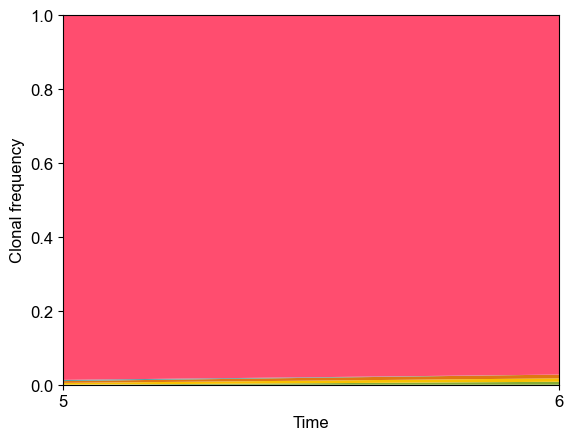

In [20]:
tm.visualize.plot(fish_data['real', 23])

## Dependence on initial frequency

In [176]:
# Subset to only the "real" scenario
df_real = df.query('scenario == "real" and ~r_median.isna()').copy()

# Make sure pass_null is numeric (0/1)
df_real["pass_null"] = df_real["pass_null"].astype(int)

# Logistic regression: pass_null ~ init_freq
logit_model_real = smf.logit("pass_null ~ init_freq", data=df_real).fit()

print(logit_model_real.summary())
print(logit_model_real.pvalues)

Optimization terminated successfully.
         Current function value: 0.519894
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              pass_null   No. Observations:                  299
Model:                          Logit   Df Residuals:                      297
Method:                           MLE   Df Model:                            1
Date:                Mon, 17 Nov 2025   Pseudo R-squ.:                 0.01505
Time:                        11:04:28   Log-Likelihood:                -155.45
converged:                       True   LL-Null:                       -157.82
Covariance Type:            nonrobust   LLR p-value:                   0.02930
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.0711      0.163      6.562      0.000       0.751       1.391
init_freq      2.2068      1.

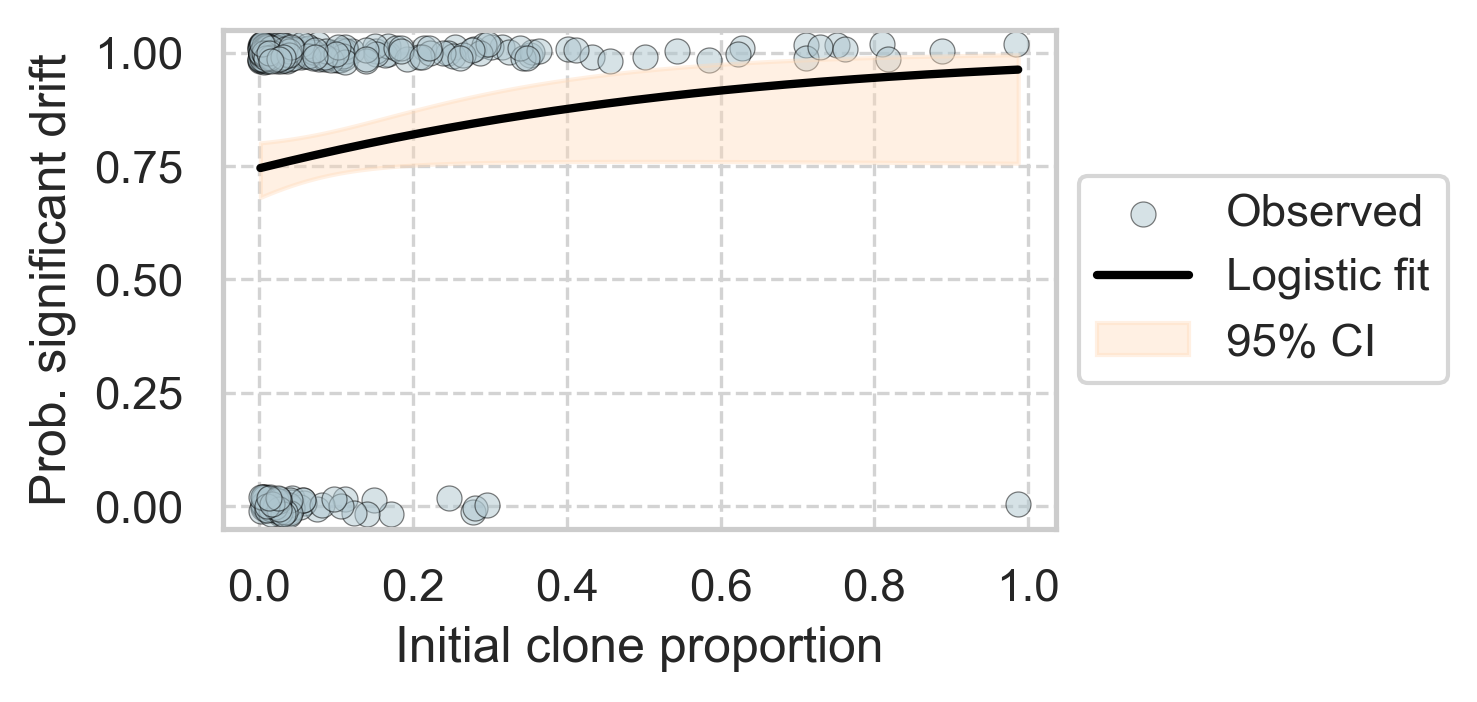

In [177]:
# Plot observed data (jittered vertically for clarity)
plt.figure(figsize=(5,2.5), dpi=300)
plt.scatter(df_real['init_freq'],
            df_real['pass_null'] + np.random.uniform(-0.02,0.02,len(df_real)),
            alpha=0.5, color="#AEC6CF", edgecolor="black", linewidth=0.3,
            label="Observed")

# Plot logistic curve
plt.plot(x_vals, pred_summary['predicted'], color="black", linewidth=2, label="Logistic fit")

# Add confidence/error bands with a different color
plt.fill_between(x_vals,
                 pred_summary['ci_lower'],
                 pred_summary['ci_upper'],
                 color="#FFDAB9", alpha=0.4, label="95% CI")  # peach color

# Labels and styling
plt.xlabel("Initial clone proportion")
plt.ylabel("Prob. significant drift")
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle="--", linewidth=0.8, color="lightgray")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

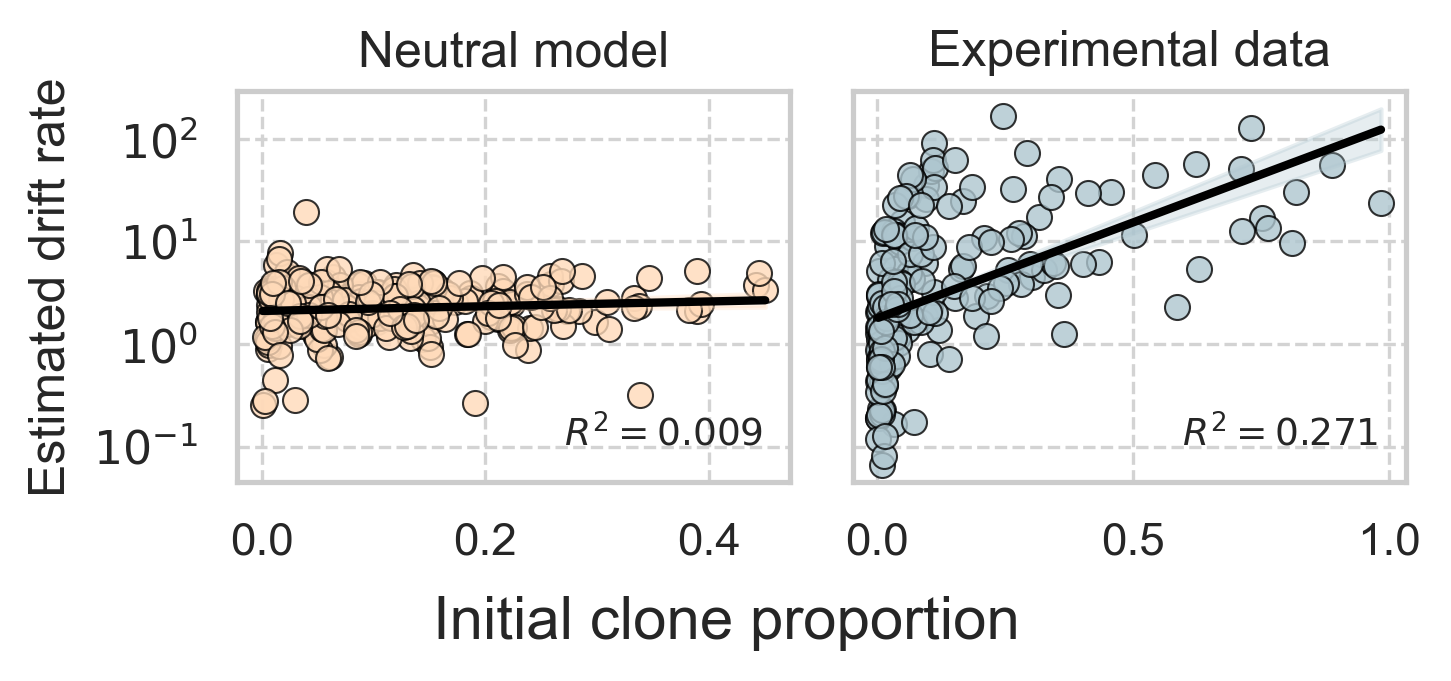

In [179]:
# Subset
compare_sim = "n1000_r2.5_y6"
real = df.query('scenario == "real" and ~r_median.isna() and r_median > 0').copy()
sim  = df.query('scenario == @compare_sim and ~r_median.isna() and r_median > 0 and fish < 30').copy()

# Fit regressions
slope_real, intercept_real, r_real, p_real, stderr_real = linregress(real['init_freq'], real['log_r_median'])
slope_sim, intercept_sim, r_sim, p_sim, stderr_sim = linregress(sim['init_freq'], sim['log_r_median'])

# Pastel palette
pastel_blue   = "#AEC6CF"  # soft blue
pastel_orange = "#FFDAB9"  # peach
line_color    = "#000000"  # muted gray for regression lines

# X values for smooth line
x_real = np.linspace(real['init_freq'].min(), real['init_freq'].max(), 200)
x_sim  = np.linspace(sim['init_freq'].min(), sim['init_freq'].max(), 200)

# Predicted values
y_real = intercept_real + slope_real * x_real
y_sim  = intercept_sim + slope_sim * x_sim

# Error regions (±1 stderr on slope, approximate)
y_real_upper = intercept_real + (slope_real + stderr_real) * x_real
y_real_lower = intercept_real + (slope_real - stderr_real) * x_real

y_sim_upper = intercept_sim + (slope_sim + stderr_sim) * x_sim
y_sim_lower = intercept_sim + (slope_sim - stderr_sim) * x_sim

# Plot
fig, axes = plt.subplots(1, 2, figsize=(5,2.5), dpi=300, sharey=True)

# Sim scenario
axes[0].scatter(sim['init_freq'], sim['log_r_median'], color=pastel_orange, alpha=0.8, edgecolor="black", linewidth=0.5)
axes[0].plot(x_sim, y_sim, color=line_color, linewidth=2)
axes[0].fill_between(x_sim, y_sim_lower, y_sim_upper, color=pastel_orange, alpha=0.3)
axes[0].set_title(f"Neutral model")
axes[0].set_ylabel("Estimated drift rate")

# Real scenario
axes[1].scatter(real['init_freq'], real['log_r_median'], color=pastel_blue, alpha=0.8, edgecolor="black", linewidth=0.5)
axes[1].plot(x_real, y_real, color=line_color, linewidth=2)
axes[1].fill_between(x_real, y_real_lower, y_real_upper, color=pastel_blue, alpha=0.3)
axes[1].set_title(f"Experimental data")

# Y-axis ticks
yticks = np.arange(-1, 3)   # gives 10^-2 through 10^2
axes[0].set_yticks(yticks)
axes[0].set_yticklabels([f"$10^{{{int(y)}}}$" for y in yticks])

# Grid styling
for ax in axes:
    ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray')

fig.supxlabel("Initial clone proportion", y=0.1)

# Annotate R^2 values at bottom right of each axis
axes[0].text(0.95, 0.075, f"$R^2 = {r_sim**2:.3f}$",
             transform=axes[0].transAxes, ha='right', va='bottom', fontsize=9)
axes[1].text(0.95, 0.075, f"$R^2 = {r_real**2:.3f}$",
             transform=axes[1].transAxes, ha='right', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [180]:
df_hypothesis = df.query('~r_median.isna() and r_median > 0 and scenario in ["real", "n1000_r2.5_y6"]')
df_hypothesis = df_hypothesis[~((df_hypothesis['scenario'] == "n1000_r2.5_y6") & (df_hypothesis['fish'] >= 30))]

import statsmodels.formula.api as smf
model = smf.ols("log_r_median ~ init_freq * scenario", data=df_hypothesis).fit()
print(model.summary())
print(model.pvalues)

                            OLS Regression Results                            
Dep. Variable:           log_r_median   R-squared:                       0.249
Model:                            OLS   Adj. R-squared:                  0.244
Method:                 Least Squares   F-statistic:                     52.95
Date:                Mon, 17 Nov 2025   Prob (F-statistic):           1.42e-29
Time:                        11:04:48   Log-Likelihood:                -273.91
No. Observations:                 483   AIC:                             555.8
Df Residuals:                     479   BIC:                             572.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

In [ ]:
df_hypothesis = df.query('~r_median.isna() and r_median > 0 and scenario in ["real", "n1000_r2.5_y6"]')
df_hypothesis = df_hypothesis[~((df_hypothesis['scenario'] == "n1000_r2.5_y6") & (df_hypothesis['fish'] >= 30))]

import statsmodels.formula.api as smf
model = smf.ols("log_r_median ~ init_freq * scenario", data=df_hypothesis).fit()
print(model.summary())
print(model.pvalues)